# Prova 1: Simulazione Monte Carlo

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

# Stile comune del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})

## Attività 1: costruzione del modello

Non negative function!
Simmetric function!
Funzione finita: True
mu(0) compatibile con Io + B: True


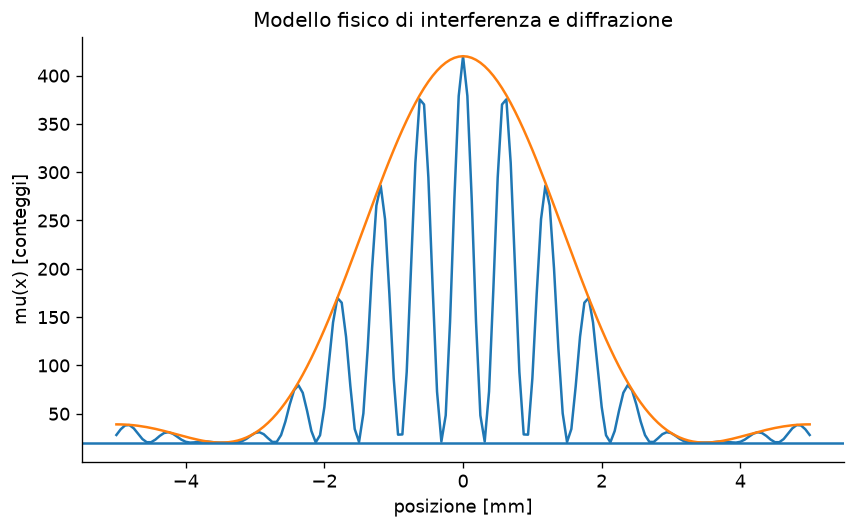

In [3]:
points = np.array(np.linspace(-5, +5, 161))
B=20 #fondo uniforme
Io=400 #scala del segnale
alpha=0.9 #larghezza inviluppo
delta=5.2 #frequenza spaziale del range
def E(x):
    return pow(np.sinc(alpha*x/np.pi), 2)

def C(x):
    return pow(np.cos(delta*x), 2)

def mu(x): #numero medio di conteggi atteso nel punto x
    return B + Io*E(x)*C(x)
positive = 0
symmetric=0
for i in range(161):
    if(mu(points[i])<0): positive += 1
    if(mu(points[i])!=mu(points[-1-i])): symmetric +=1

if(positive!=0): #controllo funzione positiva
    print("Negative function!")
else: 
    print("Non negative function!")

if(symmetric!=0): #controllo funzione è simmetrica 
    print("Non simmetric function!")
else: 
    print("Simmetric function!")

print("Funzione finita:", np.all(np.isfinite(mu(points)))) #controllo funzione finita
print("mu(0) compatibile con Io + B:", np.isclose(mu(0), Io + B)) #controllo compatibilità


    
plt.plot(points, mu(points))
plt.plot(points, B+Io*E(points))
plt.axhline(B)
plt.xlabel('posizione [mm]')
plt.ylabel('mu(x) [conteggi]')
plt.title('Modello fisico di interferenza e diffrazione')
plt.show()




Attività 2: 

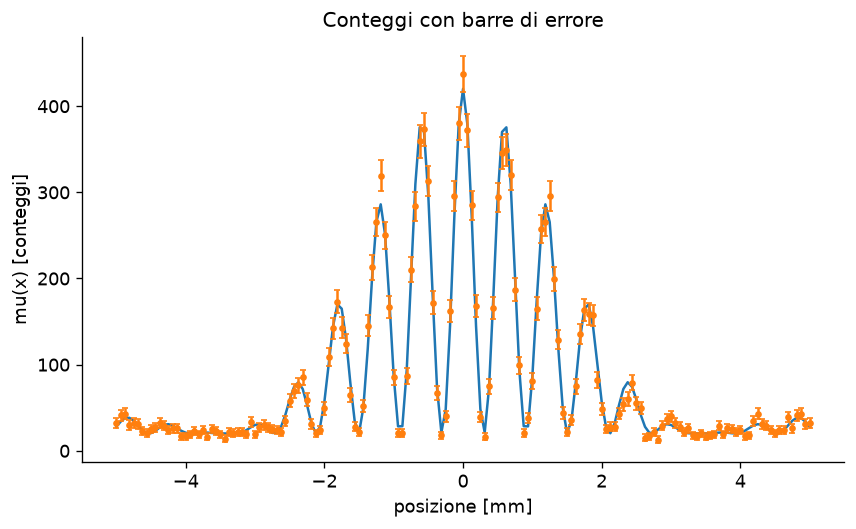

-79.45239534267876
85.81056109444035


In [4]:


rng= np.random.default_rng(seed=42)
n= np.array(rng.poisson(mu(points)))
error= np.maximum(np.sqrt(n),1.0)

plt.plot(points, mu(points))
plt.errorbar(points, n, yerr=error, fmt='o', markersize=3, capsize=2)
plt.xlabel('posizione [mm]')
plt.ylabel('mu(x) [conteggi]')
plt.title('Conteggi con barre di errore')
plt.show()


Nc=sum(n[62:100])
muc=sum(mu(points[62:100]))

print(Nc-muc)
print(np.sqrt(muc))



Attività 3

86.38252814275673
85.81056109444035


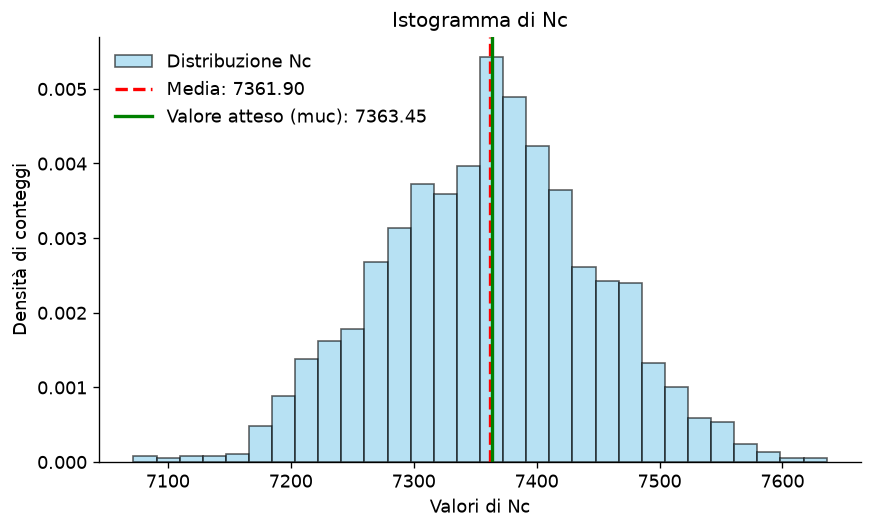

In [5]:

rng = np.random.default_rng()
Nc_arr = np.zeros(2000)  
for i in range(2000):
    Nc_arr[i] = sum(rng.poisson(mu(points[62:100])))

mean= sum(Nc_arr)/2000
dev_std= np.sqrt(sum(pow(Nc_arr-mean,2)/1999))
mean_err = dev_std/np.sqrt(2000)
scarto = (mean - muc)/muc

print(dev_std)
print(np.sqrt(muc))


plt.hist(Nc_arr, bins=30, density=True, alpha=0.6, color='skyblue', edgecolor='black', label='Distribuzione Nc')
plt.axvline(mean, color='red', linestyle='dashed', linewidth=2, label=f'Media: {mean:.2f}')
plt.axvline(muc, color='green', linestyle='solid', linewidth=2, label=f'Valore atteso (muc): {muc:.2f}')
plt.xlabel('Valori di Nc')
plt.ylabel('Densità di conteggi')
plt.title('Istogramma di Nc')
plt.legend()
plt.show() 
    


# Prova 2: fit e diagnostica

stampa parametri attività 1 su un file e inizia qui leggendoli dal file di testo

Tutti i controlli sono stati passati


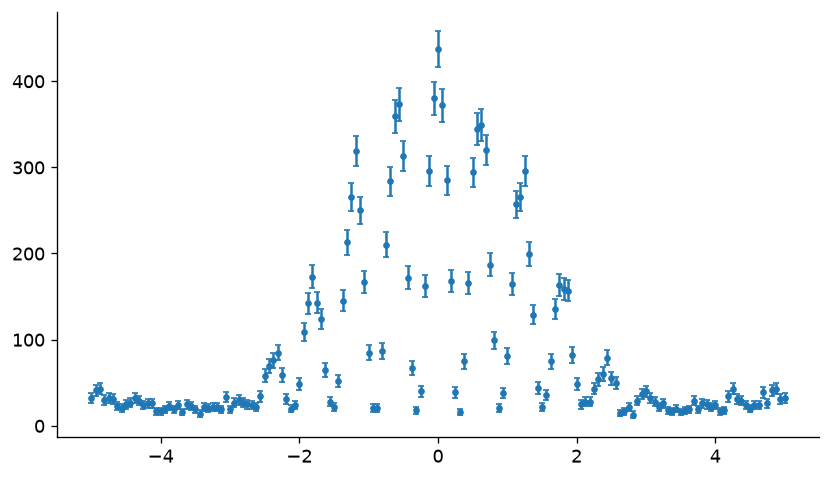

In [ ]:
matrice_dati=np.column_stack((points, n, np.sqrt(n)))
np.savetxt('data.txt', matrice_dati, delimiter='\t', header='x\ty\tsigma_y')
dati=np.genfromtxt("data.txt", delimiter='\t', names=True)
x=dati["x"]
y=dati["y"]
sigma_y=dati["sigma_y"]

def verifica (x,y,sigma_y) :
    if not (len(x)==len(y)==len(sigma_y)):
        raise ValueError("Array di lunghezze diverse")
    if not (np.all(np.isfinite(x)) and np.all(np.isfinite(y)) and np.all(np.isfinite(sigma_y))):
            raise ValueError("Array con valori non finiti")
    if not np.all(sigma_y>0):
            raise ValueError("Gli errori sono negativi")
    if not np.all(np.diff(x)>0):
            raise ValueError("Posizioni non ordinate")
    print("Tutti i controlli sono stati passati")
    return True

verifica(x,y,sigma_y)

fondo= np.min(y)
massimo= np.max(y)



plt.errorbar(x,y,yerr=sigma_y,fmt='o', markersize=3, capsize=2)
plt.show()

Attività 2:

In [ ]:
B_teo= np.median(y)
I_teo = np.max(y) - B_teo

lower = [0.0,0.0,0.10,1.0] #B>0, I>0, alfa>0.1 , delta>1.0 
upper=[np.inf,np.inf, 3.0,12.0] # B e I posono tendere a infinito, alfa<3.0, delta<12.0







Attività 3: